In [ ]:
"""
Autoencoder for the Diabetes Dataset
=====================================
Complete implementation covering:
 Task 1: Data Loading
 Task 2: Data Preprocessing
 Task 3: Autoencoder Design
 Task 4: Model Training
 Task 5: Performance Evaluation
 Task 6: Visualization
 + Latent-dimension experiment (2, 4, 8)

Dataset: sklearn's built-in Diabetes dataset (442 samples, 10 numerical features).
This is used instead of downloading from Kaggle so the script runs anywhere
without needing an API key. All numeric preprocessing / autoencoder logic
is identical to what you'd apply to the Kaggle version.
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)



In [ ]:

# -----------------------------------------------------------------------
# TASK 1: DATA LOADING
# -----------------------------------------------------------------------
print("=" * 70)
print("TASK 1: DATA LOADING")
print("=" * 70)

data = load_diabetes(as_frame=True)
df = data.frame.drop(columns=["target"])  # keep only feature columns

print(f"\nNumber of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")
print(f"\nColumn names:\n{list(df.columns)}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nFirst five records:\n{df.head()}")
print(f"\nMissing values per column:\n{df.isnull().sum()}")


TASK 1: DATA LOADING

Number of rows: 442
Number of columns: 10

Column names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Data types:
age    float64
sex    float64
bmi    float64
bp     float64
s1     float64
s2     float64
s3     float64
s4     float64
s5     float64
s6     float64
dtype: object

First five records:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Mis

In [ ]:
# -----------------------------------------------------------------------
# TASK 2: DATA PREPROCESSING
# -----------------------------------------------------------------------
print("\n" + "=" * 70)
print("TASK 2: DATA PREPROCESSING")
print("=" * 70)

# Handle missing values (none present in this dataset, but code is generic)
if df.isnull().sum().sum() > 0:
    df = df.fillna(df.mean(numeric_only=True))
    print("Missing values were filled with column means.")
else:
    print("No missing values found.")

# All columns here are already numerical; no ID / categorical columns to drop
numerical_features = df.select_dtypes(include=[np.number]).columns.tolist()
X = df[numerical_features].values
print(f"\nNumerical features selected ({len(numerical_features)}): {numerical_features}")

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train/test split (also carve out a validation set from training data)
X_train_full, X_test = train_test_split(X_scaled, test_size=0.2, random_state=SEED)
X_train, X_val = train_test_split(X_train_full, test_size=0.2, random_state=SEED)

print(f"\nTraining set shape:   {X_train.shape}")
print(f"Validation set shape: {X_val.shape}")
print(f"Test set shape:       {X_test.shape}")

n_features = X_train.shape[1]



TASK 2: DATA PREPROCESSING
No missing values found.

Numerical features selected (10): ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']

Training set shape:   (282, 10)
Validation set shape: (71, 10)
Test set shape:       (89, 10)


In [ ]:
# -----------------------------------------------------------------------
# TASK 3: AUTOENCODER DESIGN
# -----------------------------------------------------------------------
def build_autoencoder(input_dim, latent_dim):
    """Builds a symmetric encoder-decoder autoencoder."""
    inputs = Input(shape=(input_dim,), name="input_layer")

    # Encoder: at least two layers
    x = Dense(16, activation="relu", name="encoder_layer_1")(inputs)
    x = Dense(8, activation="relu", name="encoder_layer_2")(x)

    # Bottleneck / latent layer
    latent = Dense(latent_dim, activation="relu", name="latent_layer")(x)

    # Decoder: at least two layers
    x = Dense(8, activation="relu", name="decoder_layer_1")(latent)
    x = Dense(16, activation="relu", name="decoder_layer_2")(x)

    # Output layer: same number of neurons as input features
    outputs = Dense(input_dim, activation="linear", name="output_layer")(x)

    autoencoder = Model(inputs, outputs, name=f"autoencoder_latent{latent_dim}")
    encoder = Model(inputs, latent, name=f"encoder_latent{latent_dim}")

    autoencoder.compile(optimizer=Adam(learning_rate=0.001), loss="mse")
    return autoencoder, encoder


print("\n" + "=" * 70)
print("TASK 3: AUTOENCODER ARCHITECTURE (example, latent_dim=4)")
print("=" * 70)
example_model, _ = build_autoencoder(n_features, latent_dim=4)
example_model.summary()




TASK 3: AUTOENCODER ARCHITECTURE (example, latent_dim=4)


Model: "autoencoder_latent4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 10)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer_1 (Dense)         │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_layer_2 (Dense)         │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_layer (Dense)            │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_layer_1 (Dense)         │ (None, 8)              │            40 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_layer_2 (Dense)         │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 10)             │           170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 702 (2.74 KB)

 Trainable params: 702 (2.74 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# -----------------------------------------------------------------------
# TASK 4 & 5: TRAINING + EVALUATION FOR MULTIPLE LATENT DIMENSIONS
# -----------------------------------------------------------------------
print("\n" + "=" * 70)
print("TASK 4 & 5: TRAINING AND EVALUATION (latent dims = 2, 4, 8)")
print("=" * 70)

latent_dims = [2, 4, 8]
results = {}          # latent_dim -> metrics dict
histories = {}        # latent_dim -> keras History
reconstructions = {}  # latent_dim -> reconstructed test data

for ld in latent_dims:
    print(f"\n--- Training autoencoder with latent_dim = {ld} ---")
    model, encoder = build_autoencoder(n_features, latent_dim=ld)

    history = model.fit(
        X_train, X_train,
        validation_data=(X_val, X_val),
        epochs=100,
        batch_size=16,
        verbose=0
    )
    histories[ld] = history

    # Reconstruct test data
    X_test_recon = model.predict(X_test, verbose=0)
    reconstructions[ld] = X_test_recon

    # Metrics
    mse = mean_squared_error(X_test, X_test_recon)
    mae = mean_absolute_error(X_test, X_test_recon)
    rmse = np.sqrt(mse)

    # Per-sample reconstruction error (mean squared error per row)
    per_sample_error = np.mean(np.square(X_test - X_test_recon), axis=1)

    results[ld] = {
        "model": model,
        "encoder": encoder,
        "mse": mse,
        "mae": mae,
        "rmse": rmse,
        "per_sample_error": per_sample_error,
    }

    print(f"Latent dim {ld} -> MSE: {mse:.4f} | MAE: {mae:.4f} | RMSE: {rmse:.4f}")

# Summary table comparing latent dimensions
print("\n" + "-" * 50)
print("SUMMARY: Reconstruction performance vs latent dimension")
print("-" * 50)
summary_df = pd.DataFrame({
    "Latent Dim": latent_dims,
    "MSE": [results[ld]["mse"] for ld in latent_dims],
    "MAE": [results[ld]["mae"] for ld in latent_dims],
    "RMSE": [results[ld]["rmse"] for ld in latent_dims],
})
print(summary_df.to_string(index=False))

# Pick the "main" latent dimension (4) for the detailed plots below
MAIN_LD = 4
main_history = histories[MAIN_LD]
main_recon = reconstructions[MAIN_LD]
main_errors = results[MAIN_LD]["per_sample_error"]

print(f"\nPer-sample reconstruction error (latent_dim={MAIN_LD}), first 10 test samples:")
for i, err in enumerate(main_errors[:10]):
    print(f"  Sample {i}: {err:.5f}")



TASK 4 & 5: TRAINING AND EVALUATION (latent dims = 2, 4, 8)

--- Training autoencoder with latent_dim = 2 ---
Latent dim 2 -> MSE: 0.4517 | MAE: 0.5184 | RMSE: 0.6721

--- Training autoencoder with latent_dim = 4 ---
Latent dim 4 -> MSE: 0.2738 | MAE: 0.3832 | RMSE: 0.5233

--- Training autoencoder with latent_dim = 8 ---


Latent dim 8 -> MSE: 0.1757 | MAE: 0.3106 | RMSE: 0.4191

--------------------------------------------------
SUMMARY: Reconstruction performance vs latent dimension
--------------------------------------------------
 Latent Dim      MSE      MAE     RMSE
          2 0.451667 0.518353 0.672062
          4 0.273808 0.383158 0.523267
          8 0.175653 0.310614 0.419110

Per-sample reconstruction error (latent_dim=4), first 10 test samples:
  Sample 0: 0.22254
  Sample 1: 0.33126
  Sample 2: 0.46379
  Sample 3: 0.80585
  Sample 4: 0.05874
  Sample 5: 0.07921
  Sample 6: 0.77892
  Sample 7: 0.19018
  Sample 8: 0.44441
  Sample 9: 0.28861


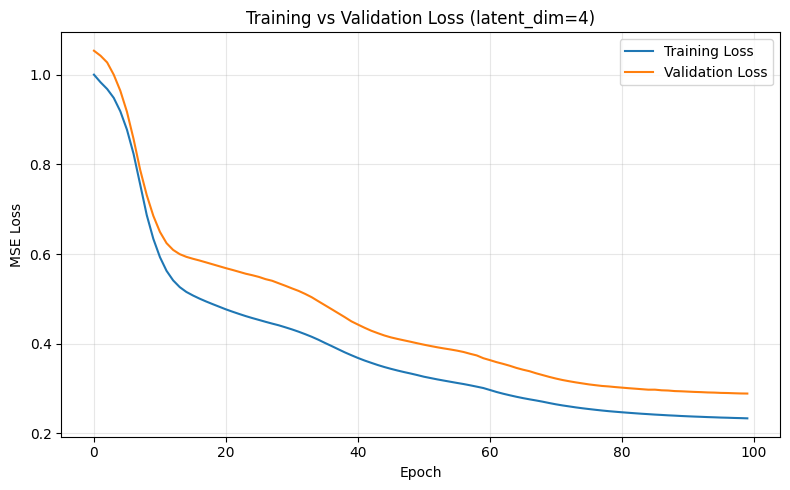

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(main_history.history["loss"], label="Training Loss")
plt.plot(main_history.history["val_loss"], label="Validation Loss")
plt.title(f"Training vs Validation Loss (latent_dim={MAIN_LD})")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot1_training_vs_validation_loss.png", dpi=150)
plt.show()

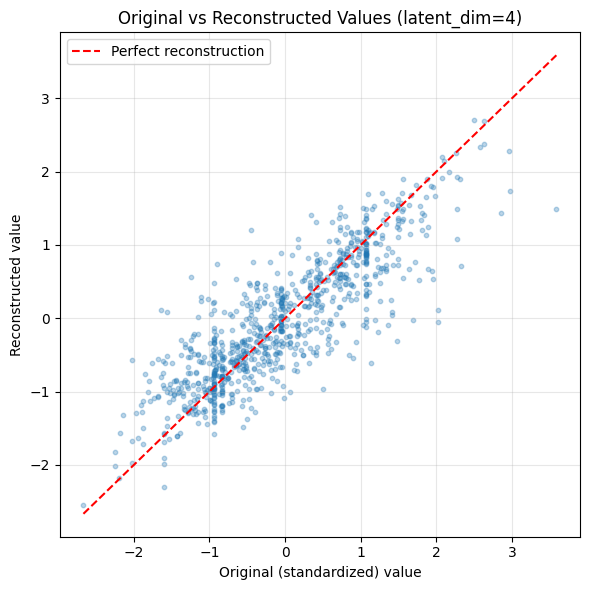

In [ ]:
plt.figure(figsize=(6, 6))
plt.scatter(X_test.flatten(), main_recon.flatten(), alpha=0.3, s=10)
min_v = min(X_test.min(), main_recon.min())
max_v = max(X_test.max(), main_recon.max())
plt.plot([min_v, max_v], [min_v, max_v], "r--", label="Perfect reconstruction")
plt.title(f"Original vs Reconstructed Values (latent_dim={MAIN_LD})")
plt.xlabel("Original (standardized) value")
plt.ylabel("Reconstructed value")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot2_original_vs_reconstructed.png", dpi=150)
plt.show()

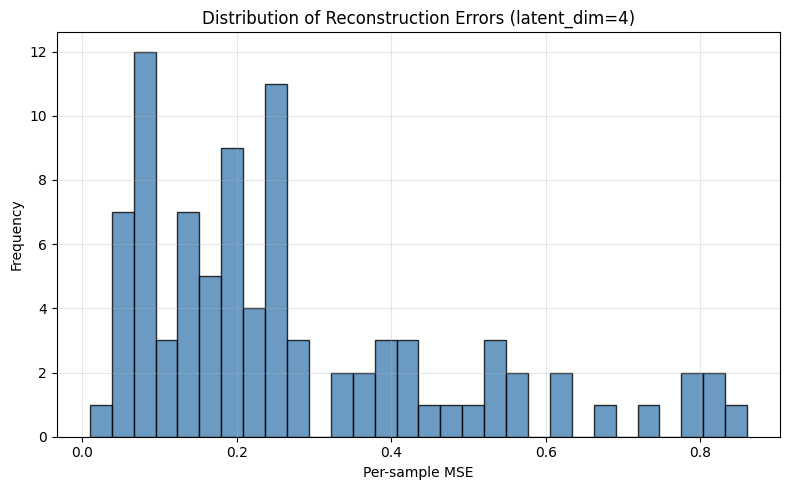

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(main_errors, bins=30, color="steelblue", edgecolor="black", alpha=0.8)
plt.title(f"Distribution of Reconstruction Errors (latent_dim={MAIN_LD})")
plt.xlabel("Per-sample MSE")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plot3_reconstruction_error_distribution.png", dpi=150)
plt.show()

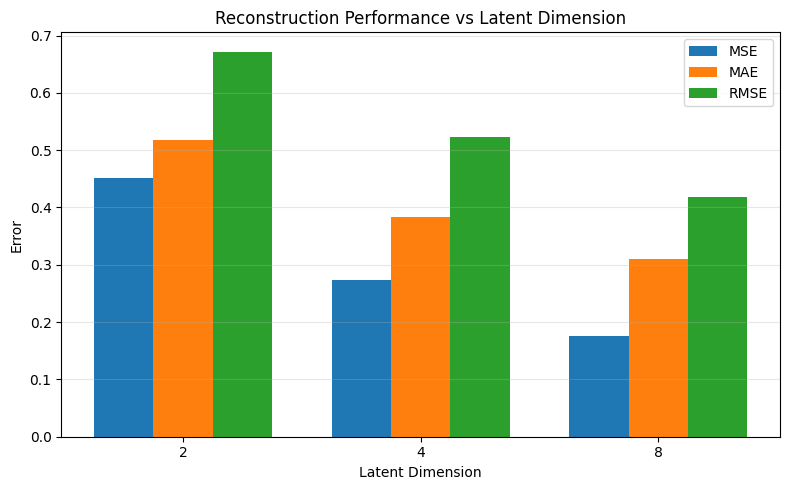

In [ ]:
plt.figure(figsize=(8, 5))
width = 0.25
x_pos = np.arange(len(latent_dims))
plt.bar(x_pos - width, [results[ld]["mse"] for ld in latent_dims], width, label="MSE")
plt.bar(x_pos, [results[ld]["mae"] for ld in latent_dims], width, label="MAE")
plt.bar(x_pos + width, [results[ld]["rmse"] for ld in latent_dims], width, label="RMSE")
plt.xticks(x_pos, [str(ld) for ld in latent_dims])
plt.xlabel("Latent Dimension")
plt.ylabel("Error")
plt.title("Reconstruction Performance vs Latent Dimension")
plt.legend()
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig("plot4_latent_dim_comparison.png", dpi=150)
plt.show()